# **Upload dataset langsung ke Colab**

In [ ]:
from google.colab import files

uploaded = files.upload()

# **Ekstrak dataset**

In [ ]:
from google.colab import drive
import zipfile
import os
import shutil

# 1. Sambungkan Google Drive
drive.mount('/content/drive')

# 2. Hapus folder ekstrak sebelumnya yang salah isi
if os.path.exists("/content/dataset_mobilenet_6kelas"):
    shutil.rmtree("/content/dataset_mobilenet_6kelas")

# 3. Path file ZIP yang benar di Drive
zip_path = "/content/drive/MyDrive/CornGuard/dataset_mobilenet_6kelas.zip"
extract_path = "/content"

# 4. Ekstrak file
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

DATASET_DIR = "/content"
print("Dataset berhasil diekstrak.")
print("Isi folder:", os.listdir(DATASET_DIR))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset berhasil diekstrak.
Isi folder: ['.config', 'drive', 'classification', 'train', 'test', 'valid', 'export_model_6kelas', 'sample_data']


# **Aktifkan GPU**

In [ ]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# **Lanjutkan training**

In [ ]:
DATASET_DIR = "/content"

# **Instalasi library**

In [ ]:
!pip install -q tensorflow scikit-learn matplotlib seaborn tf2onnx onnx

# Import library dan konfigurasi

In [ ]:
import os
import json
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.utils.class_weight import compute_class_weight

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Diperbarui ke subfolder 'classification' karena struktur hasil ekstrak zip
DATASET_DIR = "/content/dataset_mobilenet_6kelas/classification"
OUTPUT_DIR = "/content/export_model_6kelas"

os.makedirs(OUTPUT_DIR, exist_ok=True)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

CLASS_NAMES = [
    "Blight",
    "Bulai",
    "Common_Rust",
    "Gray_Leaf_Spot",
    "Healthy",
    "Anomali"
]

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
print("Dataset ditemukan:", os.path.exists(DATASET_DIR))
if os.path.exists(DATASET_DIR):
    print("Isi subfolder dataset:", os.listdir(DATASET_DIR))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Dataset ditemukan: False


# **Memuat dataset training, validasi, dan testing**

In [ ]:
DATASET_DIR = "/content"

train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATASET_DIR, "train"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=CLASS_NAMES,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

valid_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATASET_DIR, "valid"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=CLASS_NAMES,
    label_mode="int",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATASET_DIR, "test"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=CLASS_NAMES,
    label_mode="int",
    shuffle=False
)

print("Urutan kelas:", train_ds.class_names)

Found 6280 files belonging to 6 classes.
Found 1319 files belonging to 6 classes.
Found 1270 files belonging to 6 classes.
Urutan kelas: ['Blight', 'Bulai', 'Common_Rust', 'Gray_Leaf_Spot', 'Healthy', 'Anomali']


# **Menghitung class weight**

In [ ]:
jumlah_kelas = []

for nama_kelas in CLASS_NAMES:
    folder = Path(DATASET_DIR) / "train" / nama_kelas

    jumlah = sum(
        1 for f in folder.rglob("*")
        if f.is_file() and f.suffix.lower() in {
            ".jpg", ".jpeg", ".png", ".bmp", ".webp"
        }
    )

    jumlah_kelas.append(jumlah)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(CLASS_NAMES)),
    y=np.concatenate([
        np.full(jumlah, i)
        for i, jumlah in enumerate(jumlah_kelas)
    ])
)

class_weight_dict = {
    i: float(weight)
    for i, weight in enumerate(class_weights)
}

for nama, jumlah, weight in zip(
    CLASS_NAMES, jumlah_kelas, class_weights
):
    print(f"{nama}: {jumlah} gambar | Weight: {weight:.4f}")

Blight: 648 gambar | Weight: 1.6152
Bulai: 920 gambar | Weight: 1.1377
Common_Rust: 814 gambar | Weight: 1.2858
Gray_Leaf_Spot: 333 gambar | Weight: 3.1431
Healthy: 748 gambar | Weight: 1.3993
Anomali: 2817 gambar | Weight: 0.3716


**Optimasi dataset**

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
valid_ds = valid_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

# Membangun model **MobileNetV2**

In [ ]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10)
])

base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)
x = layers.Rescaling(1./127.5, offset=-1)(x)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.25)(x)

outputs = layers.Dense(
    6,
    activation="softmax",
    name="predictions"
)(x)

model = Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

# **Training tahap pertama**

In [ ]:
checkpoint_awal = ModelCheckpoint(
    os.path.join(OUTPUT_DIR, "best_model_awal.keras"),
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

early_stop_awal = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_awal = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.000001,
    verbose=1
)

history_awal = model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=15,
    class_weight=class_weight_dict,
    callbacks=[
        checkpoint_awal,
        early_stop_awal,
        reduce_lr_awal
    ]
)

Epoch 1/15
197/197 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.7446 - loss: 0.7874
Epoch 1: val_accuracy improved from None to 0.95375, saving model to /content/export_model_6kelas/best_model_awal.keras

Epoch 1: finished saving model to /content/export_model_6kelas/best_model_awal.keras
197/197 ━━━━━━━━━━━━━━━━━━━━ 38s 121ms/step - accuracy: 0.8823 - loss: 0.4265 - val_accuracy: 0.9538 - val_loss: 0.1436 - learning_rate: 0.0010
Epoch 2/15
196/197 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9630 - loss: 0.1878
Epoch 2: val_accuracy improved from 0.95375 to 0.97119, saving model to /content/export_model_6kelas/best_model_awal.keras

Epoch 2: finished saving model to /content/export_model_6kelas/best_model_awal.keras
197/197 ━━━━━━━━━━━━━━━━━━━━ 20s 99ms/step - accuracy: 0.9632 - loss: 0.1774 - val_accuracy: 0.9712 - val_loss: 0.0910 - learning_rate: 0.0010
Epoch 3/15
196/197 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.9669 - loss: 0.1672
Epoch 3: val_accuracy did not improve

# **Fine-tuning MobileNetV2**

In [ ]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

checkpoint_finetune = ModelCheckpoint(
    os.path.join(OUTPUT_DIR, "best_model_finetune.keras"),
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

early_stop_finetune = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_finetune = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.0000001,
    verbose=1
)

history_finetune = model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=10,
    class_weight=class_weight_dict,
    callbacks=[
        checkpoint_finetune,
        early_stop_finetune,
        reduce_lr_finetune
    ]
)

Epoch 1/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9803 - loss: 0.1073
Epoch 1: val_accuracy improved from None to 0.97195, saving model to /content/export_model_6kelas/best_model_finetune.keras

Epoch 1: finished saving model to /content/export_model_6kelas/best_model_finetune.keras
197/197 ━━━━━━━━━━━━━━━━━━━━ 32s 120ms/step - accuracy: 0.9815 - loss: 0.1004 - val_accuracy: 0.9719 - val_loss: 0.0748 - learning_rate: 1.0000e-05
Epoch 2/10
196/197 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.9809 - loss: 0.0995
Epoch 2: val_accuracy improved from 0.97195 to 0.98029, saving model to /content/export_model_6kelas/best_model_finetune.keras

Epoch 2: finished saving model to /content/export_model_6kelas/best_model_finetune.keras
197/197 ━━━━━━━━━━━━━━━━━━━━ 39s 112ms/step - accuracy: 0.9804 - loss: 0.0981 - val_accuracy: 0.9803 - val_loss: 0.0637 - learning_rate: 1.0000e-05
Epoch 3/10
196/197 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.9789 - loss: 0.0949
Epoch 3: val

Simpan model terbaik

In [ ]:
model_awal = tf.keras.models.load_model(
    os.path.join(OUTPUT_DIR, "best_model_awal.keras")
)

model_finetune = tf.keras.models.load_model(
    os.path.join(OUTPUT_DIR, "best_model_finetune.keras")
)

loss_awal, acc_awal = model_awal.evaluate(valid_ds, verbose=0)
loss_finetune, acc_finetune = model_finetune.evaluate(valid_ds, verbose=0)

if acc_finetune >= acc_awal:
    best_model = model_finetune
    print("Model terbaik: Fine-tuning")
else:
    best_model = model_awal
    print("Model terbaik: Training awal")

best_model.save(
    os.path.join(OUTPUT_DIR, "corn_mobilenetv2_6kelas.keras")
)

print("Akurasi validasi model awal:", acc_awal * 100, "%")
print("Akurasi validasi fine-tuning:", acc_finetune * 100, "%")
print("Model terbaik berhasil disimpan.")

Model terbaik: Fine-tuning
Akurasi validasi model awal: 97.95299172401428 %
Akurasi validasi fine-tuning: 98.25625419616699 %
Model terbaik berhasil disimpan.


Grafik hasil training

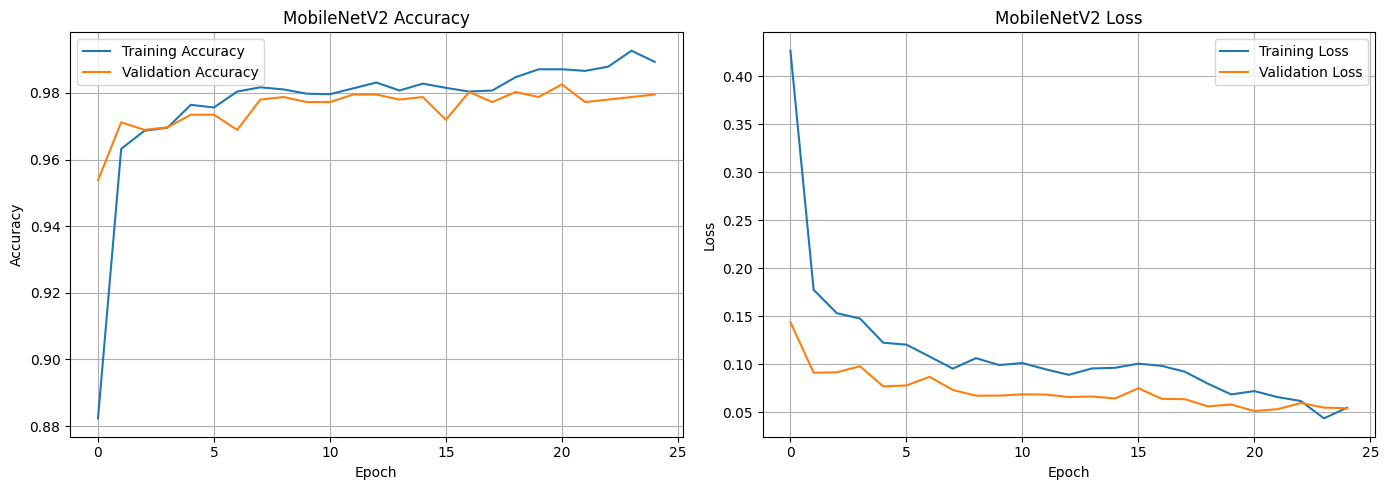

In [ ]:
acc = history_awal.history["accuracy"] + history_finetune.history["accuracy"]
val_acc = history_awal.history["val_accuracy"] + history_finetune.history["val_accuracy"]

loss = history_awal.history["loss"] + history_finetune.history["loss"]
val_loss = history_awal.history["val_loss"] + history_finetune.history["val_loss"]

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(acc, label="Training Accuracy")
plt.plot(val_acc, label="Validation Accuracy")
plt.title("MobileNetV2 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(loss, label="Training Loss")
plt.plot(val_loss, label="Validation Loss")
plt.title("MobileNetV2 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

Simpan hasil training

In [ ]:
metadata = {
    "input_size": 224,
    "classes": CLASS_NAMES,
    "preprocess": "none",
    "resize": "stretch"
}

with open(
    os.path.join(OUTPUT_DIR, "classifier_meta.json"),
    "w"
) as f:
    json.dump(metadata, f, indent=4)

print("Metadata berhasil disimpan.")

Metadata berhasil disimpan.


In [34]:
!pip install -q tf2onnx

import tensorflow as tf, tf2onnx

model = tf.keras.models.load_model("export_model_6kelas/corn_mobilenetv2_6kelas.keras")
spec = (tf.TensorSpec((None, 224, 224, 3), tf.float32, name="input"),)
tf2onnx.convert.from_keras(model, input_signature=spec, opset=13, output_path="classifier.onnx")

(ModelProto(ir_version=7, opset_import={'': 13, 'ai.onnx.ml': 2}, producer_name='tf2onnx', producer_version='1.17.0 None', graph=GraphProto('tf2onnx', input=<1 inputs>, output=<1 outputs>, initializer=<129 initializers>, node=<143 nodes>)),
 None)